# 4.3 Continuous Probability Distributions

**Goal:** identify eight continuous distribution families, compute interval probabilities and quantiles, and translate rate, scale, and shape parameterizations.

**Prerequisites:** notebook 4.1, exponentials/logarithms, and integration from Module 0.

**Runtime:** Python 3.10+ with NumPy, SciPy, and Matplotlib. If needed, install them in your chosen environment with `python3 -m pip install numpy scipy matplotlib`. Open in JupyterLab, Jupyter Notebook, or VS Code with a Python kernel. Use **Restart Kernel and Run All** to reproduce the saved text and figure outputs. Every notebook is self-contained; random examples use a local fixed seed. All data are synthetic or idealized model calculations, and no downloads are needed.

## Contents
1. Uniform
2. Normal
3. Standard normal
4. Exponential
5. Gamma
6. Beta
7. Weibull
8. Log-normal
9. Distribution selection and AI/ML applications
10. Practice and solutions

**Conventions:** all scale and standard-deviation parameters below are positive. All listed PDFs are zero outside their stated support. General-purpose SciPy distributions allow a `loc` shift; examples keep `loc=0` unless a location is intrinsic to the formula. A shift does not replace the scientific reasoning needed to choose a support.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, integrate, special

plt.rcParams.update({"figure.figsize": (7, 4), "axes.titlesize": 12,
                     "axes.labelsize": 10, "font.size": 10})
rng = np.random.default_rng(2026)

## 1. Uniform Distribution

$X\sim\operatorname{Uniform}(a,b)$ with a<b has constant density on [a,b]:
$$f(x)=\frac1{b-a},\quad \mathbb E[X]=\frac{a+b}2,\quad\operatorname{Var}(X)=\frac{(b-a)^2}{12}.$$
Its CDF is 0 below a, $(x-a)/(b-a)$ on [a,b], and 1 above b. Equal-length subintervals inside the support have equal probability; exact points still have probability zero. The quantile is $Q(u)=a+u(b-a)$ for $0<u<1$.

**Worked example:** a modeled arrival offset is uniform between 2 and 8 minutes. The chance it falls between 3 and 5 is $(5-3)/(8-2)=1/3$, mean 5 and variance 3.

SciPy uses `uniform(loc=a,scale=b-a)`, so `scale` is width, not the upper endpoint. Uniform is a substantive assumption of constant density; merely knowing lower and upper limits does not prove it. Uniform random numbers also underlie inverse-CDF sampling methods.

In [2]:
uniform = stats.uniform(loc=2, scale=6)
print("P(3 <= X <= 5):", uniform.cdf(5)-uniform.cdf(3))
print("Mean/variance:", uniform.mean(), uniform.var())
print("90th percentile:", uniform.ppf(0.9))
assert np.isclose(uniform.var(), 3)

P(3 <= X <= 5): 0.33333333333333337
Mean/variance: 5.0 3.0
90th percentile: 7.4


## 2. Normal Distribution

$X\sim\mathcal N(\mu,\sigma^2)$ has support $\mathbb R$, location $\mu$, variance $\sigma^2$, and
$$f(x)=\frac1{\sigma\sqrt{2\pi}}\exp\left[-\frac{(x-\mu)^2}{2\sigma^2}\right].$$
Its mean, median, and mode equal $\mu$, and variance equals $\sigma^2$. It is symmetric and has skewness 0 and excess kurtosis 0. Normality is a specific model, not a consequence of symmetry alone.

**Worked example:** a measurement is modeled as $\mathcal N(100,15^2)$. The interval [85,115] is one SD around the mean and has probability about 0.682689. A cutoff of 130 is two SDs above the mean; the upper-tail probability is about 0.022750.

SciPy `norm(loc=mu,scale=sigma)` expects **standard deviation**, not variance. A normal model allows negative values; it may be implausible for strongly right-skewed nonnegative quantities or values near a physical lower bound. In regression, a normal error likelihood is a conditional modeling assumption about errors, not a requirement that all features be normal.

In [3]:
normal = stats.norm(loc=100, scale=15)
print("P(85 <= X <= 115):", normal.cdf(115)-normal.cdf(85))
print("P(X > 130):", normal.sf(130))
print("Central 95% model interval:", normal.ppf([0.025, 0.975]))
assert np.isclose(normal.var(), 225)

P(85 <= X <= 115): 0.6826894921370859
P(X > 130): 0.022750131948179198
Central 95% model interval: [ 70.60054023 129.39945977]


## 3. Standard Normal Distribution

$Z\sim\mathcal N(0,1)$ has density $\phi(z)=e^{-z^2/2}/\sqrt{2\pi}$ and CDF $\Phi(z)$. If X is normal with mean $\mu$ and SD $\sigma$, then $Z=(X-\mu)/\sigma$ is standard normal, so
$$P(a\le X\le b)=\Phi((b-\mu)/\sigma)-\Phi((a-\mu)/\sigma).$$

**Worked example:** under the preceding model, 130 maps to z=2. The 97.5th percentile of the standard normal is approximately 1.959964, giving the normal central 95% interval $\mu\pm1.959964\sigma$.

Subtracting a mean and dividing by an SD produces a standardized variable for any finite-variance distribution, but it becomes **standard normal only if the original variable is normal**. Standardization does not repair skewness or heavy tails.

In [4]:
z = (130-100)/15
print("z-score:", z, "standard-normal upper tail:", stats.norm.sf(z))
print("97.5th standard-normal percentile:", stats.norm.ppf(0.975))
assert np.isclose(stats.norm.sf(z), normal.sf(130))

z-score: 2.0 standard-normal upper tail: 0.022750131948179198
97.5th standard-normal percentile: 1.959963984540054


## 4. Exponential Distribution

With rate $\lambda>0$, $X\sim\operatorname{Exponential}(\lambda)$ has support $x\ge0$ and
$$f(x)=\lambda e^{-\lambda x},\quad F(x)=1-e^{-\lambda x},\quad S(x)=e^{-\lambda x},$$
$$\mathbb E[X]=1/\lambda,\qquad\operatorname{Var}(X)=1/\lambda^2.$$
The rate has units inverse to x; the scale is $\theta=1/\lambda$. SciPy uses `expon(scale=1/lambda)`.

**Worked example:** a homogeneous Poisson process has event rate 2 per hour. The wait to its next event is exponential with mean 0.5 hours. Probability of waiting over 0.75 hours is $e^{-1.5}\approx0.223130$.

It is memoryless: $P(X>s+t\mid X>s)=P(X>t)$ for s,t≥0. Its hazard $f(x)/S(x)$ is the constant rate $\lambda$. Many real lifetimes have aging or changing conditions, so exponential memorylessness may be inappropriate. A geometric trial count is its discrete waiting-time analogue, not the same variable.

In [5]:
rate = 2.0
exponential = stats.expon(scale=1/rate)
print("P(wait > 0.75 hours):", exponential.sf(0.75))
print("Mean/variance:", exponential.mean(), exponential.var())
assert np.isclose(exponential.sf(1.25)/exponential.sf(0.5), exponential.sf(0.75))

P(wait > 0.75 hours): 0.22313016014842982
Mean/variance: 0.5 0.25


## 5. Gamma Distribution

Use **shape** $\alpha>0$ and **scale** $\theta>0$:
$$f(x)=\frac{x^{\alpha-1}e^{-x/\theta}}{\Gamma(\alpha)\theta^\alpha},\quad x>0,$$
$$\mathbb E[X]=\alpha\theta,\qquad\operatorname{Var}(X)=\alpha\theta^2.$$
Here $\Gamma(\alpha)=\int_0^\infty t^{\alpha-1}e^{-t}\,dt$, and $\Gamma(m)=(m-1)!$ for a positive integer m. A rate parameterization uses $\beta=1/\theta$, giving mean $\alpha/\beta$. **Shape is not rate.**

The gamma distribution with shape 1 is exponential. For integer shape m and scale $1/\lambda$, it is the sum of m independent exponential waiting times with common rate $\lambda$, often called Erlang. Noninteger shapes remain valid without an integer-event-count interpretation. Its density can diverge near zero when shape<1 while still integrating to 1.

**Worked example:** time to the third event in a homogeneous rate-2-per-hour Poisson process is Gamma(shape=3,scale=0.5), with mean 1.5 hours and variance 0.75. For three events by time t, the waiting-time and count formulations agree: $P(T_3\le t)=P(N(t)\ge3)$.

The [official gamma documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.gamma.html) explains the shape/scale interface. Do not pass rate 2 as `scale=2` when you mean scale 0.5.

In [6]:
gamma = stats.gamma(a=3, scale=0.5)
print("P(third event by 2 hours):", gamma.cdf(2))
print("Equivalent count probability:", stats.poisson(mu=4).sf(2))
print("Mean/variance:", gamma.mean(), gamma.var())
assert np.isclose(gamma.cdf(2), stats.poisson(mu=4).sf(2))
assert np.isclose(stats.gamma(a=1, scale=0.5).cdf(0.75), exponential.cdf(0.75))

P(third event by 2 hours): 0.7618966944464557
Equivalent count probability: 0.7618966944464557
Mean/variance: 1.5 0.75


## 6. Beta Distribution

With $\alpha,\beta>0$, $X\sim\operatorname{Beta}(\alpha,\beta)$ is supported on [0,1], with interior density
$$f(x)=\frac{x^{\alpha-1}(1-x)^{\beta-1}}{B(\alpha,\beta)},\quad0<x<1,$$
where $B(\alpha,\beta)=\Gamma(\alpha)\Gamma(\beta)/\Gamma(\alpha+\beta)$.
$$\mathbb E[X]=\frac\alpha{\alpha+\beta},\quad\operatorname{Var}(X)=\frac{\alpha\beta}{(\alpha+\beta)^2(\alpha+\beta+1)}.$$
It can be uniform (both parameters 1), symmetric, skewed, or U-shaped. Densities can be unbounded near endpoints for some parameter values; point probabilities at endpoints are still zero for this continuous family.

**Worked example: Bayesian uncertainty about a probability.** With prior $p\sim\operatorname{Beta}(2,2)$ and 8 successes, 2 failures from conditionally IID Bernoulli trials, posterior $p\mid D\sim\operatorname{Beta}(10,4)$. Its mean is 10/14. The distribution describes uncertainty about p; a future binary outcome is still Bernoulli conditional on p. The posterior predictive success probability is the posterior mean, not a new beta-distributed binary label.

Posterior quantiles give a **credible interval for the parameter** under this model, not an interval containing 95% of binary future outcomes and not an automatically frequentist confidence interval. Dependence, label errors, and changing p can invalidate this simple likelihood.

In [7]:
prior = stats.beta(a=2, b=2)
posterior = stats.beta(a=2+8, b=2+2)
print("Posterior mean success probability:", posterior.mean())
print("95% equal-tail credible interval for p:", posterior.ppf([0.025, 0.975]))
print("Posterior probability p > 0.5:", posterior.sf(0.5))
assert np.isclose(posterior.mean(), 10/14)

Posterior mean success probability: 0.7142857142857143
95% equal-tail credible interval for p: [0.46186846 0.90907961]
Posterior probability p > 0.5: 0.953857421875


## 7. Weibull Distribution

Use shape $k>0$ and scale $\lambda>0$ (this $\lambda$ is a scale, not the exponential rate):
$$f(x)=\frac{k}{\lambda}\left(\frac{x}{\lambda}\right)^{k-1}e^{-(x/\lambda)^k},\quad x>0,$$
$$F(x)=1-e^{-(x/\lambda)^k},\quad S(x)=e^{-(x/\lambda)^k},$$
$$\mathbb E[X]=\lambda\Gamma(1+1/k),$$
$$\operatorname{Var}(X)=\lambda^2\left[\Gamma(1+2/k)-\Gamma(1+1/k)^2\right].$$
The hazard is $(k/\lambda)(x/\lambda)^{k-1}$: decreasing for k<1, constant for k=1, and increasing for k>1. At k=1 it is exponential with mean/scale $\lambda$, hence exponential rate $1/\lambda$.

**Worked example:** a lifetime model has k=2 and scale 10 hours. Probability of surviving beyond 10 hours is $e^{-1}\approx0.367879$. The scale is the point with CDF $1-e^{-1}$ (about 63.2%), not generally the mean or median.

SciPy `weibull_min(c=k,scale=lambda)` implements this form; see the [official Weibull documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.weibull_min.html). More flexible hazard behavior can suit lifetime modeling, but censored observations require a suitable likelihood rather than pretending every recorded observation is an exact failure time.

In [8]:
k, scale = 2.0, 10.0
weibull = stats.weibull_min(c=k, scale=scale)
print("P(lifetime > 10 hours):", weibull.sf(10))
print("Mean/variance:", weibull.mean(), weibull.var())
manual_mean = scale*special.gamma(1+1/k)
assert np.isclose(weibull.mean(), manual_mean)
assert np.isclose(weibull.sf(10), math.exp(-1))

P(lifetime > 10 hours): 0.36787944117144233
Mean/variance: 8.862269254527579 21.460183660255183


## 8. Log-Normal Distribution

If $Y=\ln X\sim\mathcal N(\mu,\sigma^2)$ with $\sigma>0$, then X is log-normal with x>0 and
$$f(x)=\frac1{x\sigma\sqrt{2\pi}}\exp\left[-\frac{(\ln x-\mu)^2}{2\sigma^2}\right].$$
Its parameters describe the **log variable**, not the original mean and SD:
$$\mathbb E[X]=e^{\mu+\sigma^2/2},\quad\operatorname{median}(X)=e^\mu,$$
$$\operatorname{Var}(X)=(e^{\sigma^2}-1)e^{2\mu+\sigma^2}.$$
Products of positive factors can motivate log-scale models. The distribution is right-skewed and cannot represent exact zeros without an additional model component. Taking logs of nonnegative data does not automatically make them normal.

**Worked example:** let log duration have $\mu=1,\sigma=0.5$. Original-scale median is $e\approx2.71828$, mean is $e^{1.125}\approx3.08022$, and $P(X>e^{1.5})=P(Z>1)\approx0.158655$.

SciPy uses `lognorm(s=sigma,scale=exp(mu),loc=0)`. The [official log-normal documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.lognorm.html) specifies this mapping. Passing `scale=mu` would be wrong for this convention.

In [9]:
mu_log, sigma_log = 1.0, 0.5
lognormal = stats.lognorm(s=sigma_log, scale=np.exp(mu_log))
print("Original-scale mean:", lognormal.mean(), "median:", lognormal.median())
print("Tail probability:", lognormal.sf(np.exp(1.5)))
assert np.isclose(lognormal.mean(), np.exp(mu_log+sigma_log**2/2))
assert np.isclose(lognormal.sf(np.exp(1.5)), stats.norm.sf(1))

Original-scale mean: 3.080216848918031 median: 2.718281828459045
Tail probability: 0.15865525393145707


## Compare the shapes

The following PDFs use different horizontal units and ranges, so panel heights should not be compared as event probabilities. Each full density integrates to 1; a displayed finite window can omit some tail area. The standard-normal panel is a parameter-specific normal distribution rather than a separate location-scale family.

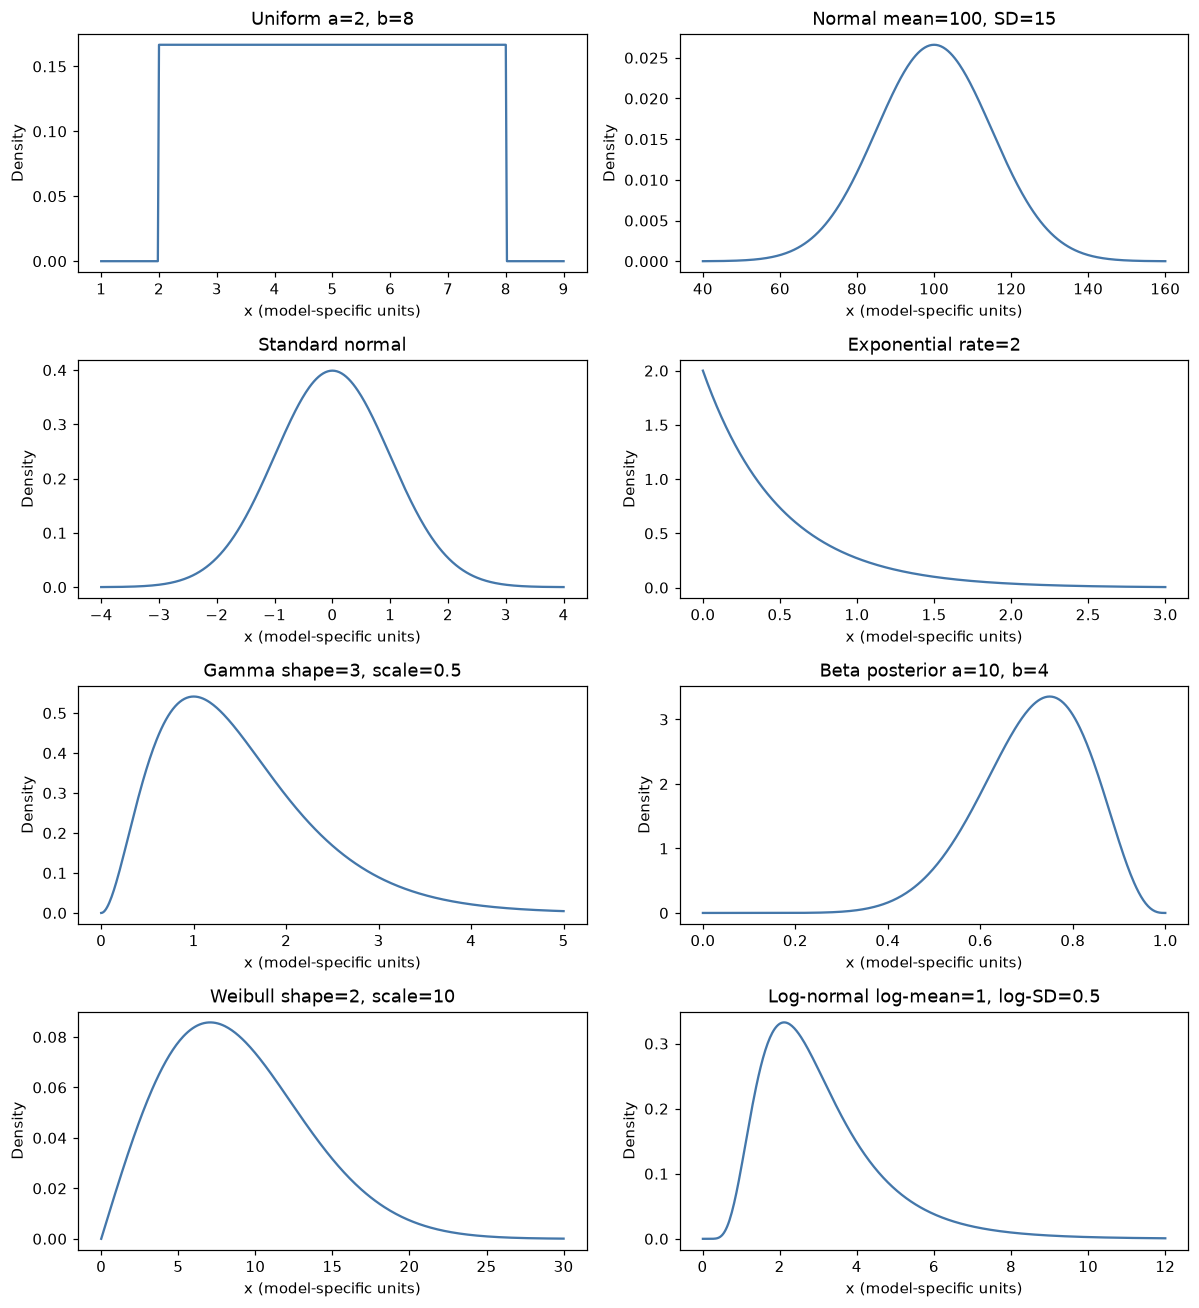

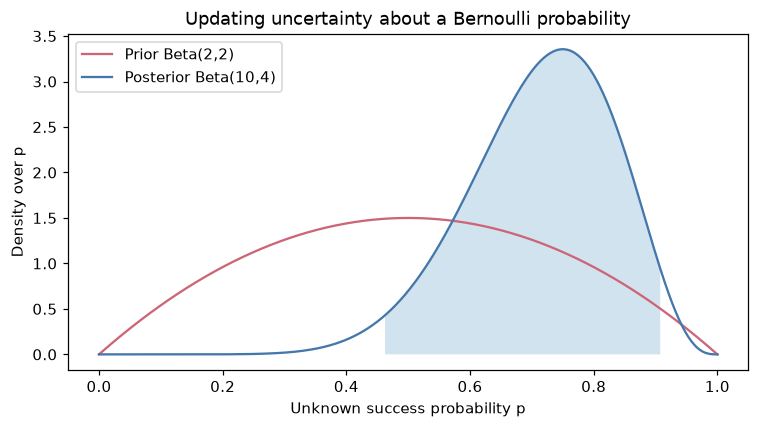

In [10]:
models = [("Uniform a=2, b=8", uniform, np.linspace(1, 9, 401)),
          ("Normal mean=100, SD=15", normal, np.linspace(40, 160, 401)),
          ("Standard normal", stats.norm(), np.linspace(-4, 4, 401)),
          ("Exponential rate=2", exponential, np.linspace(0, 3, 401)),
          ("Gamma shape=3, scale=0.5", gamma, np.linspace(0, 5, 401)),
          ("Beta posterior a=10, b=4", posterior, np.linspace(0, 1, 401)),
          ("Weibull shape=2, scale=10", weibull, np.linspace(0, 30, 401)),
          ("Log-normal log-mean=1, log-SD=0.5", lognormal, np.linspace(0.01, 12, 401))]
fig, axes = plt.subplots(4, 2, figsize=(11, 12))
for ax, (title, model, grid) in zip(axes.flat, models):
    ax.plot(grid, model.pdf(grid), color="#4477AA")
    ax.set(title=title, xlabel="x (model-specific units)", ylabel="Density")
fig.tight_layout()
plt.show()
# Credible-interval figure shows parameter uncertainty, not outcome frequency.
grid = np.linspace(0, 1, 401)
lo, hi = posterior.ppf([0.025, 0.975])
fig, ax = plt.subplots()
ax.plot(grid, prior.pdf(grid), label="Prior Beta(2,2)", color="#CC6677")
ax.plot(grid, posterior.pdf(grid), label="Posterior Beta(10,4)", color="#4477AA")
ax.fill_between(grid, posterior.pdf(grid), where=(grid >= lo) & (grid <= hi), alpha=0.2)
ax.set(title="Updating uncertainty about a Bernoulli probability", xlabel="Unknown success probability p", ylabel="Density over p")
ax.legend()
fig.tight_layout()
plt.show()

## 9. Distribution choice and AI/ML applications

| Family | Typical support | Modeling question |
|---|---|---|
| Uniform | Bounded interval | Is constant density a defensible bounded model? |
| Normal / standard normal | All real numbers | Are symmetric real errors or latent variables plausible? |
| Exponential | Nonnegative | Is constant-hazard waiting reasonable? |
| Gamma | Positive | Is a flexible positive waiting/amount model appropriate? |
| Beta | Unit interval | Is uncertainty about a probability or a bounded proportion continuous? |
| Weibull | Nonnegative | Does lifetime risk increase or decrease with age? |
| Log-normal | Positive | Are multiplicative variation and log-normality plausible? |

Gaussian Naive Bayes uses a normal conditional density for each feature within each class, together with conditional-independence assumptions. Generative models often sample standard-normal latent variables and transform them into observations. Beta priors model uncertainty over Bernoulli probabilities. Gamma and log-normal likelihoods can describe positive targets with different tail structures.

Variational inference often chooses a tractable approximation family for a posterior; that family need not equal the observation distribution. A normal approximation for a latent variable does not imply that observed labels or measurements are normal. Notebook 4.4 includes a small variational approximation example and its limits.

## Practice

1. Uniform on [4,10]: find mean, variance, and $P(5\le X\le8)$.
2. $X\sim\mathcal N(50,4^2)$. Standardize 58 and write $P(X>58)$ using $\Phi$.
3. Exponential rate 0.5 per hour: find mean and $P(X>4)$.
4. Gamma shape 4 and rate 2: give the scale, mean, and variance.
5. Beta(3,7) prior with 6 successes and 4 failures: give posterior parameters and mean.
6. Weibull k=1 and scale 5: identify the equivalent exponential rate.
7. Log-normal log-mean 0 and log-SD 1: find original-scale median and mean.
8. Why is a beta distribution over a success probability different from a Bernoulli outcome distribution?
9. Can standardizing a log-normal sample guarantee standard-normal values?

## Solutions

1. Mean 7, variance $6^2/12=3$, probability $3/6=1/2$.
2. z=2; $P(X>58)=1-\Phi(2)\approx0.022750$.
3. Mean 2 hours; survival $e^{-0.5(4)}=e^{-2}\approx0.135335$.
4. Scale 1/2; mean $4/2=2$; variance $4/2^2=1$.
5. Beta(9,11); mean $9/20=0.45$ under the conditionally IID Bernoulli model.
6. Rate 1/5 per time unit; scale and rate are reciprocals.
7. Median $e^0=1$; mean $e^{1/2}\approx1.648721$.
8. Beta describes continuous uncertainty over p∈[0,1]; Bernoulli describes a binary result conditional on p. They play different model roles.
9. No. Standardization shifts and rescales; it does not remove skewness. A log transformation has a separate role and still requires model checking.

**Readiness check:** identify support, distinguish rate from scale and log parameters from original moments, and interpret credible intervals for the correct quantity.

**Next:** [4.4 Important Distribution Concepts](4_Important-Distribution-Concepts.ipynb).